# Sharing results: sidecars

A year after a paper, someone asks which snapshot, which units and which Mera version produced
Figure 3. Every file Mera writes for you answers that by itself: next to it sits a **sidecar**, a
small readable `<file>.meta.json` with what the file holds, where its data came from and what ran.
This page shows the sidecar and how to read it back, how to give a figure one, and how to turn a
whole folder into one record for publishing. [Exporting Data](exporting_data.md) covers the file
formats themselves.

Mera keeps one record of where a result came from, at three levels:

| level | the record | page |
|:--|:--|:--|
| one object | `provenance(gas)`, carried in memory by every Mera result | [Provenance](provenance.md) |
| one file | a sidecar, `<file>.meta.json`, next to every file Mera saves | [Sharing Results & Sidecars](export_sidecars.md) |
| one folder | `bundle(".")`, one record of a whole analysis, for publishing | [Sharing Results & Sidecars](export_sidecars.md#One-record-for-the-whole-folder) |

!!! note "Why this matters"
    Reproducible work needs more than the final figure. Guidelines for FAIR simulation data
    (Findable, Accessible, Interoperable, Reusable) ask for the data behind each figure, its
    provenance, and the environment that ran, in formats any tool can read
    ([Pfalzner et al. 2026](https://arxiv.org/abs/2602.08416)). The sidecar records that without
    extra work, every time you save.

!!! tip "FAIR in 5 lines"
    Start each analysis in its own folder: `meraproject("galaxy_paper")` makes it, then start
    Julia there with `julia --project=.` (the first time: `] instantiate`). The folder keeps its
    own list of package versions, so the sidecars can record exactly what ran. Then:

    ```julia
    exportdata(m, "fig3.h5")                            # 1. saves write their sidecar by themselves
    save("fig3.png", fig); writesidecar("fig3.png", m)  # 2. a figure: one more line
    readsidecar("fig3.png")                             # 3. where a file came from
    sidecaroverview(".")                                # 4. all files of the analysis
    bundle("."; simulation=info)                        # 5. before publishing: one record, and the BibTeX
    ```

    Nothing else has to be switched on. If you skip the first step, Mera reminds you once.

In [1]:
# Example-data root. Point this at your own simulation folder, or set the
# MERA_EXAMPLES environment variable; every path below is built from it.
MERA_EXAMPLES = get(ENV, "MERA_EXAMPLES", "/Volumes/FASTStorage/Simulations/Mera-Tests");

using Mera
info = getinfo(300, joinpath(MERA_EXAMPLES, "RAMSES/mw_L10"), verbose=false)
gas  = gethydro(info, verbose=false, show_progress=false);

# All files of this page go to a fresh folder, and the page works inside it.
# In your own work this is a folder next to your script, e.g. "results/".
cd(mktempdir())

# A map and two exported files to work with; Exporting Data explains the formats.
m = projection(gas, [:sd, :T], [:Msol_pc2, :K]; pxsize=[100., :pc],
               verbose=false, show_progress=false)
exportdata(m, "fig3_maps.h5"; length_unit=:kpc,
           note="Figure 3: gas surface density and temperature")
exportdata(m, "fig3_maps.csv"; length_unit=:kpc, verbose=false)


*__   __ _______ ______   _______ 


|  |_|  |       |    _ | |   _   |
|       |    ___|   | || |  |_|  |
|       |   |___|   |_||_|       |
|       |    ___|    __  |       |
| ||_|| |   |___|   |  | |   _   |
|_|   |_|_______|___|  |_|__| |__|
Mera v1.9.0 | Julia 1.12.7 | 4 threads



[Mera] Hint: fig3_maps.h5.meta.json records where fig3_maps.h5 came from.


             readsidecar("fig3_maps.h5") shows it; sidecar(false) stops writing them.
             (shown once per session; verbose(false) silences Mera's messages)
exportdata: T, sd → fig3_maps.h5  (+ fig3_maps.h5.meta.json)


"fig3_maps.csv"

## The sidecar

[`readsidecar`](@ref) prints what a sidecar says. It also checks that the data file still matches
the SHA-256 recorded when it was written.

!!! info "SHA-256 in short"
    A SHA-256 is a fingerprint of a file: 64 characters computed from every byte of it. Change a
    single byte and the fingerprint is completely different, and two different files practically
    never share one. So when a file's SHA-256 matches the one in its sidecar, it is the file that
    was written. It says nothing about whether the content is right, only that it is unchanged.
    Outside Julia, `shasum -a 256 fig3_maps.h5` (macOS) or `sha256sum fig3_maps.h5` (Linux)
    computes the same fingerprint.

In [2]:
r = readsidecar("fig3_maps.h5")

Sidecar of fig3_maps.h5  (hdf5, projection)  data file: unchanged
  written      2026-10-25 11:54 UTC by Mera 1.9.0; Julia 1.12.7, 4 threads
  source       Mera v1.9.0 | mw_L10/output_00300 | 445.89 Myr | L=48.0 ndim=3 lmin=6 lmax=10 | ScalesType003
  simulation   /Volumes/FASTStorage/Simulations/Mera-Tests/RAMSES/mw_L10
  input files  namelist.txt, makefile.txt, patches.txt (SHA-256 recorded)
  environment  /Volumes/FASTStorage/Simulations/Notebooks/Mera-Docs/version_1.1: Project.toml and Manifest.toml (SHA-256 recorded), 23 packages
  contents     x [kpc] 481
               y [kpc] 481
               T [K] 481×481
               sd [Msol_pc2] 481×481
  note         Figure 3: gas surface density and temperature
  sidecar      fig3_maps.h5.meta.json

The line *written* names the Mera build that wrote the file, and the `environment` part of the
sidecar stores how Mera was installed: the registered release, a branch from GitHub, or a local
checkout, and whether the code is exactly the registered release. It says "not a registered
release" here because this page is built from a development checkout of Mera;
[Which build ran](provenance.md#Which-build-ran) explains the cases.

The sidecar is plain JSON, with these parts:

| part | holds |
|:--|:--|
| `file` | name, size and SHA-256 of the data file |
| `result` | what the file holds: arrays, shapes, units, the map geometry, and the format's layout |
| `source` | the [provenance](provenance.md) of the snapshot |
| `input_files` | SHA-256 of the run's `namelist.txt`, `makefile.txt`, `patches.txt`, `compilation.txt` |
| `analysis` | the Julia environment of your analysis and the script that ran (see below) |
| `environment` | Julia and Mera version, how Mera was installed, OS, CPU model, thread counts |
| `note` | your text |

Each part can be read directly:

In [3]:
println("output      : ", r["source"]["output"])
println("time        : ", round(r["source"]["time_myr"], sigdigits=5), " Myr")
println("sd unit     : ", r["result"]["arrays"]["sd"]["unit"])
println("map extent  : ", round.(Float64.(r["result"]["attributes"]["extent"]), sigdigits=6), " ",
        r["result"]["attributes"]["length_unit"])
println("namelist    : ", r["input_files"]["namelist.txt"]["sha256"])
println("julia       : ", r["environment"]["julia_version"], ", ", r["environment"]["julia_threads"], " threads")

output      : 300
time        : 445.89 Myr
sd unit     : Msol_pc2
map extent  : 

[0.0, 48.0, 0.0, 48.0] kpc
namelist    : 925c69c26386ef7814b955f77160dc82cf0004de114c8165b5b36290915b3c75
julia       : 1.12.7, 4 threads


**What is not recorded.** The host name of the machine is left out on purpose. The simulation
path is kept in full, because it is what traces the data; `anonymize=true` keeps only its last
two parts, for a sidecar you publish:

In [4]:
exportdata(m, "fig3_public.h5"; length_unit=:kpc, anonymize=true)
readsidecar("fig3_public.h5")["source"]["simulation_path"]

exportdata: T, sd → fig3_public.h5  (+ fig3_public.h5.meta.json)


".../RAMSES/mw_L10"

## Mera files and maps get sidecars too

[`savedata`](@ref), [`savemap`](@ref), [`savemovie`](@ref) and [`save_clumps`](@ref) write a
sidecar as well. For a Mera
file it lists every data type in the file; an `:append` adds to the list. Here a small sphere
around the centre keeps the file small.

In [5]:
core = subregion(gas, :sphere; radius=3., center=[:bc], range_unit=:kpc, verbose=false)
savedata(core, :write; path=".", verbose=false)
savemap(m, "fig3_maps.jld2"; verbose=false)

readsidecar("output_00300.jld2")

Sidecar of output_00300.jld2  (jld2, mera_file)  data file: unchanged
  written      2026-10-25 11:55 UTC by Mera 1.9.0; Julia 1.12.7, 4 threads
  source       Mera v1.9.0 | mw_L10/output_00300 | 445.89 Myr | L=48.0 ndim=3 lmin=6 lmax=10 | ScalesType003
  simulation   /Volumes/FASTStorage/Simulations/Mera-Tests/RAMSES/mw_L10
  input files  namelist.txt, makefile.txt, patches.txt (SHA-256 recorded)
  environment  /Volumes/FASTStorage/Simulations/Notebooks/Mera-Docs/version_1.1: Project.toml and Manifest.toml (SHA-256 recorded), 23 packages
  contents     hydro: 1136840 rows, 11 columns
  sidecar      output_00300.jld2.meta.json

## Figures

A figure is saved by the plotting package, so Mera does not see it. One more line,
[`writesidecar`](@ref), gives it the same record, taken from the result it shows:

Sidecar written → fig3.png.meta.json

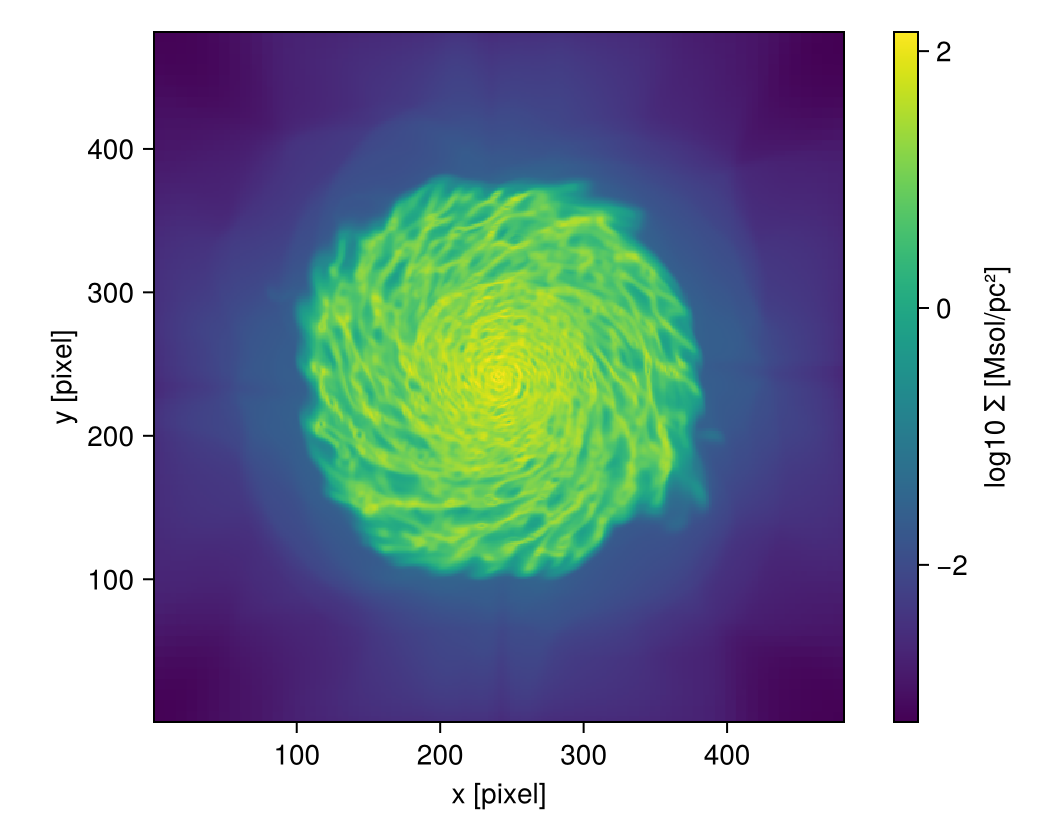

In [6]:
using CairoMakie
fig = Figure(size=(520, 420))
ax = Axis(fig[1, 1]; aspect=DataAspect(), xlabel="x [pixel]", ylabel="y [pixel]")
hm = heatmap!(ax, log10.(m.maps[:sd]))
Colorbar(fig[1, 2], hm; label="log10 Σ [Msol/pc²]")
save("fig3.png", fig)

writesidecar("fig3.png", m; note="Figure 3");
fig

For a figure with several panels, pass all its results, `writesidecar("fig4.pdf", [m1, m2, m3])`;
the sidecar then lists the snapshot of each panel. Read back, it shows what the figure was made
from:

In [7]:
readsidecar("fig3.png")

Sidecar of fig3.png  (png, figure)  data file: unchanged
  written      2026-10-25 11:55 UTC by Mera 1.9.0; Julia 1.12.7, 4 threads
  source       Mera v1.9.0 | mw_L10/output_00300 | 445.89 Myr | L=48.0 ndim=3 lmin=6 lmax=10 | ScalesType003
  simulation   /Volumes/FASTStorage/Simulations/Mera-Tests/RAMSES/mw_L10
  input files  namelist.txt, makefile.txt, patches.txt (SHA-256 recorded)
  environment  /Volumes/FASTStorage/Simulations/Notebooks/Mera-Docs/version_1.1: Project.toml and Manifest.toml (SHA-256 recorded), 23 packages
  contents     x [standard] 481
               y [standard] 481
               T [K] 481×481
               sd [Msol_pc2] 481×481
  note         Figure 3
  sidecar      fig3.png.meta.json

## An overview of a folder

[`sidecaroverview`](@ref) lists every sidecar in a folder: what each file holds, the snapshot,
and when it was written.

In [8]:
recs = sidecaroverview(".");

6 sidecar

s in .
file               kind        format  snapshot             time       written (UTC)     data file
-----------------  ----------  ------  -------------------  ---------  ----------------  ---------
fig3.png           figure      png     mw_L10/output_00300  445.9 Myr  2026-10-25 11:55  present  
fig3_maps.csv      projection  csv     mw_L10/output_00300  445.9 Myr  2026-10-25 11:54  present  
fig3_maps.h5       projection  hdf5    mw_L10/output_00300  445.9 Myr  2026-10-25 11:54  present  
fig3_maps.jld2     projection  jld2    mw_L10/output_00300  445.9 Myr  2026-10-25 11:55  present  
fig3_public.h5     projection  hdf5    mw_L10/output_00300  445.9 Myr  2026-10-25 11:54  present  
output_00300.jld2  mera_file   jld2    mw_L10/output_00300  445.9 Myr  2026-10-25 11:55  present  


## Has a file changed?

The recorded SHA-256 notices a file that was edited or replaced after it was written. Here one
line is added to the CSV, as a spreadsheet program might do on saving:

In [9]:
open("fig3_maps.csv", "a") do io
    println(io, "0,0,0,0")
end

readsidecar("fig3_maps.csv").status

:changed

`sidecaroverview(dir; verify=true)` checks every file of a folder. It is off by default, since
hashing large Mera files takes a few seconds per GB.

In [10]:
recs = sidecaroverview("."; verify=true, verbose=false)
[basename(x.file) => x.status for x in recs]

6-element Vector{Pair{String, Symbol}}:
          "fig3.png" => :unchanged
     "fig3_maps.csv" => :changed
      "fig3_maps.h5" => :unchanged
    "fig3_maps.jld2" => :unchanged
    "fig3_public.h5" => :unchanged
 "output_00300.jld2" => :unchanged

## Describing the simulation

A sidecar describes a result. [`simulationrecord`](@ref) describes the simulation behind it:
the code, box and resolution, units, cosmology, which physics was on, what the outputs hold, and
the SHA-256 of the run's input files. For RAMSES the physics comes from the namelist, with the
Fortran values cleaned up (comments removed, `.true.` and numbers parsed).

In [11]:
rec = simulationrecord(info)

Simulation record of mw_L10 (RAMSES), output 300
  box          48 kpc (48 in code units), 3-D
  resolution   levels 6..10, finest cell 46.875 pc
  time         445.89 Myr
  physics      hydro (hllc), gravity, particles, cooling, star formation, feedback
  contents     hydro, gravity, particles
  input files  namelist.txt, makefile.txt, patches.txt (SHA-256 recorded)

In [12]:
rec["physics"]["summary"]["star_formation"]

OrderedCollections.OrderedDict{String, Any} with 4 entries:
  "T2_star"  => 0
  "eps_star" => 0.01
  "m_star"   => 1
  "n_star"   => 10.0

Given the simulation folder instead, the record also lists every output with its time and size
on disk, and the outputs at which the namelist changed, for a run restarted with new settings:

In [13]:
run = simulationrecord(joinpath(MERA_EXAMPLES, "RAMSES/mw_L10"))

simulationrecord: 1 output of mw_L10


Simulation record of mw_L10 (RAMSES), output 300
  box          48 kpc (48 in code units), 3-D
  resolution   levels 6..10, finest cell 46.875 pc
  time         445.89 Myr
  physics      hydro (hllc), gravity, particles, cooling, star formation, feedback
  contents     hydro, gravity, particles
  run          1 outputs (300..300), 445.89..445.89 Myr, 5.682 GB
  input files  namelist.txt, makefile.txt, patches.txt (SHA-256 recorded)

In [14]:
for o in run["run"]["output_list"]
    println("output ", o["output"], "   ", round(o["time_myr"], sigdigits=5), " Myr   ",
            round(o["bytes"] / 1e9, sigdigits=3), " GB")
end

output 300   445.89 Myr   6.1 GB


To publish the simulation itself, [`datacite`](@ref) turns the record into DataCite metadata,
the format data repositories and DOI registration use. Mera fills in what it knows: the
technical description, sizes, formats, the creation date, and the RAMSES paper as related work.
You supply who made it, a title and a license, as keywords or in a `simulation.toml` next to the
simulation, so they are written once per run.

In [15]:
meta = datacite(run; creators=["Behrendt, Manuel"], title="Isolated Milky-Way-like disc galaxy",
                license="CC-BY-4.0", keywords=["galaxy", "interstellar medium"],
                file="datacite.json")
print(read("datacite.json", String))

{
    "schemaVersion": "http://datacite.org/schema/kernel-4",
    "types": {
        "resourceTypeGeneral": "Dataset",
        "resourceType": "Simulation output"
    },
    "titles": [
        {
            "title": "Isolated Milky-Way-like disc galaxy"
        }
    ],
    "creators": [
        {
            "name": "Behrendt, Manuel",
            "nameType": "Personal",
            "familyName": "Behrendt",
            "givenName": "Manuel"
        }
    ],
    "publisher": {
        "name": "Zenodo"
    },
    "publicationYear": "2026",
    "subjects": [
        {
            "subject": "galaxy"
        },
        {
            "subject": "interstellar medium"
        },
        {
            "subject": "numerical simulation"
        },
        {
            "subject": "RAMSES"
        }
    ],
    "dates": [
        {
            "date": "2025-06-21",
            "dateType": "Created"
        }
    ],
    "language": "en",
    "descriptions": [
        {
            "description":

## What to cite

[`citation`](@ref) gives the BibTeX for Mera at the exact version that runs, and the papers of
the code behind the data. For RAMSES that is the code paper, plus the MHD and RT papers when the
run used them. On a saved file it takes the Mera version recorded in the sidecar.

In [16]:
citation(gas)

@software{Mera_1_9_0,
  author  = {Behrendt, Manuel},
  title   = {Mera.jl: Fast, conservation-correct, code-agnostic analysis of astrophysical simulations in Julia},
  version = {1.9.0},
  year    = {2026},
  doi     = {10.5281/zenodo.3675254},
  url     = {https://github.com/ManuelBehrendt/Mera.jl}
}

@article{Teyssier2002,
  author  = {Teyssier, Romain},
  title   = {Cosmological hydrodynamics with adaptive mesh refinement. A new high resolution code called RAMSES},
  journal = {Astronomy and Astrophysics},
  volume  = {385},
  pages   = {337--364},
  year    = {2002},
  doi     = {10.1051/0004-6361:20011817}
}


In [17]:
citation("fig3.png"; file="software.bib");

## One record for the whole folder

Before the folder is published, [`bundle`](@ref) joins all its sidecars into one record,
`ro-crate-metadata.json`. It is an [RO-Crate](https://www.researchobject.org/ro-crate/), a
standard format for describing research data: every file with its size and SHA-256, and for
each file Mera wrote, what made it (the Mera version, the script and the snapshot). It also
writes `software.bib` from [`citation`](@ref) and, with `simulation=`, the simulation record.
Nothing is copied.

In [18]:
bundle("."; simulation=info, title="Sharing results example",
       creators=["Behrendt, Manuel"], license="CC-BY-4.0")

┌ Warning: These files changed after their sidecar was written: fig3_maps.csv. Write them again, or their recorded SHA-256 does not match.
└ @ Mera ~/code-github/Mera.jl/src/functions/export/bundle.jl:213


Bundle of .: 9 files, 6 with a sidecar, 1 snapshot, Mera 1.9.0
  → ./ro-crate-metadata.json


"./ro-crate-metadata.json"

The warning names the CSV that was edited above: `bundle` checks every file against the SHA-256
in its sidecar before it records it.

Authors, title and license can also live in an `analysis.toml` in the folder, so the call
becomes `bundle("."; simulation=info)`. [`meraproject`](@ref) writes one when it starts a new
analysis folder. One entry of the record, the action that wrote the figure:

In [19]:
crate = Mera.JSON3.read(read("ro-crate-metadata.json", String))
Mera.JSON3.pretty(only(e for e in crate["@graph"] if e["@id"] == "#make-fig3.png"))

{
    

"@id": "#make-fig3.png",
    "@type": "CreateAction",
    "name": "Mera wrote fig3.png",
    "instrument": [
        {
            "@id": "#mera-1.9.0"
        }
    ],
    "result": {
        "@id": "fig3.png"
    },
    "object": [
        {
            "@id": "#snapshot-mw_L10_output_00300"
        }
    ],
    "endTime": "2026-10-25T11:55:21.163"
}

## Why sidecars are on by default, and how to switch them off

A record helps only if it exists when someone asks for it, often a year later. A feature that
has to be switched on is mostly never switched on, so Mera writes the sidecar every time. It
costs little:

* it is small, about 5 KB per file;
* it is quiet: the first sidecar of a session prints one short line saying what the new file is
  and how to stop it, and after that only `exportdata` names it, in its usual line;
* it never breaks a save: if the sidecar cannot be written, you get a warning and the data file
  is still written.

There are good reasons to switch them off. On a cluster that limits the number of files, every
saved file now counts twice. And the sidecar records the simulation path (never the host name);
if that should not be public, `anonymize=true` keeps only its last two parts.

`sidecar=false` turns the sidecar off for one call. [`sidecar`](@ref) switches it for the whole
session, like [`verbose`](@ref): `sidecar(false)` at the top of a script for none,
`sidecar(nothing)` to return to each call's own keyword. To switch them off without changing a
script, set the environment variable `MERA_SIDECAR=0`, for example in a cluster job script:
`MERA_SIDECAR=0 julia analysis.jl`. The frames that `savemovie` writes with `save_frames` get no
sidecar; the movie itself does.

In [20]:
sidecar(false)
exportdata(m, "scratch.npz"; verbose=false)
println("sidecar written: ", isfile("scratch.npz.meta.json"))
sidecar(nothing);

sidecar written: false

## The analysis around the result

A result also depends on the analysis that made it: your script, and the versions of every
package it used. The `analysis` part of the sidecar records both.

* **The environment.** The SHA-256 of the active `Project.toml` and `Manifest.toml`, and the
  version of each package in the project. With those two files, anyone can rebuild exactly the
  packages that ran (`pkg> instantiate`); the fingerprints show they have the right ones.
* **The script.** Run as `julia analysis.jl`, or in JupyterLab or Jupyter Notebook 7 (which tell
  the kernel the notebook's path), the sidecar names the script and stores its SHA-256. With
  `include_script=true` it also stores the full text, or the code cells of a notebook. That is off
  by default, since a script may hold private paths or notes.

In [21]:
for (name, version) in r["analysis"]["environment"]["packages"]
    println(rpad(name, 16), version)
end

ArrayInterface  7.28.1
BenchmarkTools  1.8.0
CSVFiles        1.0.2
CairoMakie      0.15.13
CodecZlib       0.7.8
ColorSchemes    3.31.0
Conda           1.10.3
DelimitedFiles  1.9.1
FITSIO          0.17.5
FileIO          1.20.0
FortranFiles    0.6.2
GZip            0.7.1
HDF5            0.17.3
JLD             0.13.5
MAT             0.12.1
Mera            1.9.0 (path)
NPZ             0.4.3
PyCall          1.96.4
PyPlot          2.11.6
Revise          3.16.2
Serialization   1.11.0
StructArrays    0.4.2
TimerOutputs    0.5.29


This page is executed by `nbconvert`, which does not tell the kernel which notebook it runs, so
here the script is not recorded:

In [22]:
r["analysis"]["script"] === nothing

true

Run as a script, the same part reads like this:

```json
"script": {
    "kind": "script",
    "name": "analysis.jl",
    "path": "/home/me/projects/galaxy/analysis.jl",
    "sha256": "3f9a…"
}
```

**What is still not recorded.** Code typed into the REPL leaves no file behind, and VS Code
notebooks do not pass their path on. And a function you wrote yourself, such as the reducer of a
[`timeseries`](@ref) or an [`add_field`](@ref) kernel, appears only by name: the result does not
keep the code that made it. In those cases the script or notebook is still the record, so keep
it, and publish it next to the results.

**Before you publish figure data:**

- [ ] run the analysis as a script, or in JupyterLab, so the sidecars name it
- [ ] export each figure's data with `exportdata`, with a `note` naming the figure
- [ ] give each figure file its sidecar with `writesidecar`
- [ ] check the folder with `sidecaroverview(dir; verify=true)`
- [ ] use `anonymize=true` if the simulation path should not be public
- [ ] put the data files, their sidecars and the scripts or notebooks in one folder, run
      `bundle` on it, and upload it, e.g. to Zenodo
- [ ] describe the simulation with `simulationrecord`, and `datacite` if it is published too
- [ ] cite the software with the BibTeX from `citation`
- [ ] commit the `Project.toml` and `Manifest.toml` of the analysis (see [Reproducibility](reproducibility.md))

## See also

* [Provenance](provenance.md), the record in the `source` part of every sidecar
* [Exporting Data](exporting_data.md), the formats `exportdata` writes
* [Reproducibility](reproducibility.md), pinned environments and test simulations
* [MERA files](07_multi_Mera_Files.md), Mera's own format for data objects
* [`export_vtk`](@ref), for ParaView and VisIt